# 02b. Faster R-CNN — аналіз запусків

Лише збережені результати трьох запусків (`hw2_runs/faster_rcnn/<запуск>/`) і оригінальні val-кадри: без GPU і без перенавчання. Запускається локально.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image

ROOT = Path.cwd().parent.parent
RUNS = ROOT / "hw2_runs" / "faster_rcnn"
DATA = ROOT / "hw2_data"
NAMES = {"baseline": "baseline", "exp1_pos_fraction": "exp1: частка 0,5", "exp2_giou": "exp2: GIoU"}
COLORS = {"baseline": "#2a78d6", "exp1_pos_fraction": "#eb6834", "exp2_giou": "#1baf7a"}
PUBLIC_LB = {"exp2_giou": 0.22142}

metrics = {r: json.loads((RUNS / r / r / "metrics.json").read_text()) for r in NAMES}
history = {r: pd.read_csv(RUNS / r / r / "history.csv") for r in NAMES}
stages = {r: pd.read_csv(RUNS / r / r / "stages.csv", index_col=0) for r in NAMES}
val_coco = json.loads((DATA / "val" / "annotations_coco.json").read_text())
val_images = pd.DataFrame(val_coco["images"]).set_index("id")
classes = {c["id"]: c["name"] for c in val_coco["categories"]}

## 1. Підсумкова таблиця

Повний val (2 846 кадрів). `ms` — медіанний час одного кадру на Tesla T4, batch 1. `public_LB` — публічний лідерборд (надіслано лише exp2).

In [2]:
summary = pd.DataFrame({NAMES[r]: {**m["val"], "ms": m["ms_per_image"], "public_LB": PUBLIC_LB.get(r, np.nan)}
                        for r, m in metrics.items()}).T
summary[["mAP", "AP50", "AP_small", "ms", "AP75", "AP_medium", "AP_large", "mAP_test_like", "public_LB"]].round(4)

,mAP,AP50,AP_small,ms,AP75,AP_medium,AP_large,mAP_test_like,public_LB
baseline,0.1565,0.3203,0.0691,109.0962,0.1374,0.1421,0.3124,0.1717,NaN
"exp1: частка 0,5",0.1502,0.3102,0.0613,100.9779,0.1308,0.1390,0.2936,0.1679,NaN
exp2: GIoU,0.1590,0.3272,0.0647,106.2330,0.1395,0.1453,0.3034,0.1771,0.2214


**Що бачимо:** найкращий mAP — exp2 (0,159, +0,0025 до baseline), він же найкращий за AP50 і mAP «тестоподібних» кліпів. AP_small найвищий у baseline (0,069). exp1 гірший за baseline за всіма метриками. Швидкість усіх трьох — 101–109 мс/кадр. Публічний лідерборд exp2 — 0,221.

## 2. AP по класах

`n_val` — скільки об'єктів класу у val (без ігнорованих зон).

In [3]:
n_val = pd.Series([a["category_id"] for a in val_coco["annotations"] if a["iscrowd"] == 0]).map(classes).value_counts()
per_class = pd.DataFrame({NAMES[r]: m["per_class"] for r, m in metrics.items()})
per_class.insert(0, "n_val", n_val.reindex(per_class.index))
per_class.round(4)

,n_val,baseline,"exp1: частка 0,5",exp2: GIoU
person,50312,0.2252,0.2233,0.2235
bicycle,6022,0.1017,0.0925,0.1132
car,31821,0.3367,0.3389,0.3339
van,6842,0.2051,0.1810,0.1866
truck,1359,0.1581,0.1467,0.1802
tricycle,5487,0.1533,0.1521,0.1623
bus,264,0.0009,0.0004,0.0007
motor,12025,0.0711,0.0671,0.0715


**Що бачимо:** найкраще — car (~0,34) і person (~0,22), найгірше — bus (~0; у val 264 рамки), motor (~0,07), bicycle (~0,10). exp2 відносно baseline: truck +0,022, bicycle +0,012, tricycle +0,009, van −0,019.

## 3. mAP по кліпах

`width` — ширина кадру; `test_like` — кліп із шириною ≤ 1920, як у test. Останній рядок — у скількох кліпах запуск найкращий.

In [4]:
per_clip = pd.DataFrame({NAMES[r]: m["clips"] for r, m in metrics.items()})
wins = per_clip.idxmax(axis=1).value_counts().reindex(per_clip.columns, fill_value=0)
width = val_images.groupby("video")["width"].first()
per_clip.insert(0, "width", width.reindex(per_clip.index))
per_clip.insert(1, "test_like", per_clip["width"] <= 1920)
display(per_clip.round(4))
wins.to_frame("найкращий у кліпах").T

,width,test_like,baseline,"exp1: частка 0,5",exp2: GIoU
uav0000086_00000_v,1344,True,0.1217,0.1108,0.1380
uav0000117_02622_v,2720,False,0.1858,0.1759,0.1921
uav0000137_00458_v,2688,False,0.2292,0.2239,0.2319
uav0000182_00000_v,1344,True,0.1332,0.1313,0.1387
uav0000268_05773_v,3840,False,0.0902,0.0846,0.0816
uav0000305_00000_v,1904,True,0.1970,0.2021,0.2137
uav0000339_00001_v,1904,True,0.2179,0.2181,0.2178


,baseline,"exp1: частка 0,5",exp2: GIoU
найкращий у кліпах,1,1,5


**Що бачимо:** exp2 найкращий у 5 з 7 кліпів, зокрема в 3 з 4 «тестоподібних» (у 0339 усі три однакові). Найслабший кліп — 0268 (3840 px, mAP 0,08–0,09), і там exp2 гірший за baseline. Різниця між кліпами (0,08–0,23) значно більша, ніж між запусками.

## 4. Криві навчання

Loss на train і mAP на кожному 5-му кадрі val (571 кадр) після кожної епохи. Пунктир — learning rate зменшено в 10 разів (після 7-ї і 10-ї епох). Loss різних запусків напряму не порівнюється: exp1 рахує його на іншій вибірці, exp2 — іншою функцією втрат.

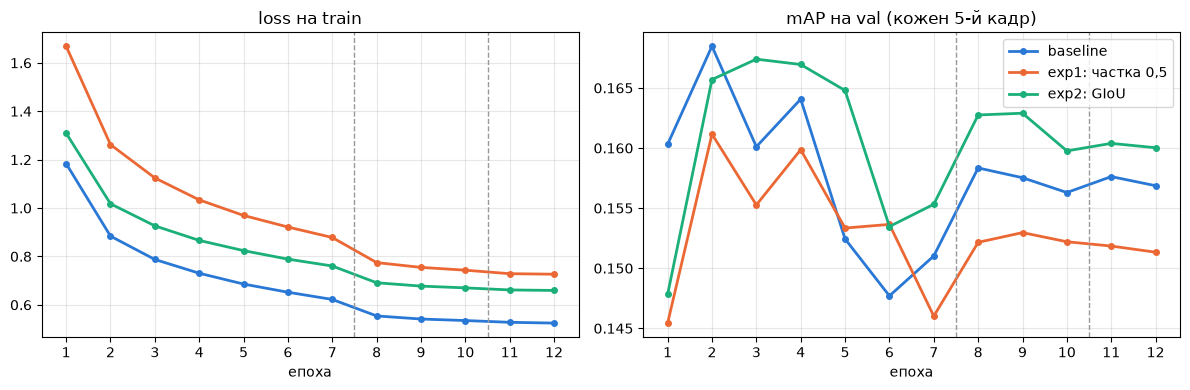

,найкраща епоха,найкращий mAP,mAP 12-ї епохи
baseline,2.0,0.1685,0.1569
"exp1: частка 0,5",2.0,0.1612,0.1513
exp2: GIoU,3.0,0.1674,0.1600


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, col, title in zip(axes, ("loss", "mAP"), ("loss на train", "mAP на val (кожен 5-й кадр)")):
    for r, h in history.items():
        ax.plot(h["epoch"], h[col], marker="o", markersize=4, linewidth=2, color=COLORS[r], label=NAMES[r])
    for x in (7.5, 10.5):
        ax.axvline(x, color="#999999", linestyle="--", linewidth=1)
    ax.set(title=title, xlabel="епоха", xticks=range(1, 13))
    ax.grid(alpha=0.3)
axes[1].legend()
plt.tight_layout()
plt.show()
pd.DataFrame({NAMES[r]: {"найкраща епоха": int(h.loc[h["mAP"].idxmax(), "epoch"]), "найкращий mAP": h["mAP"].max(),
                         "mAP 12-ї епохи": h["mAP"].iloc[-1]} for r, h in history.items()}).T.round(4)

**Що бачимо:** loss на train падає весь час. mAP на val найвищий на 2–3-й епосі (0,161–0,169), найнижчий — на 6–7-й, після зниження learning rate (8-ма епоха) частково відновлюється, але на 12-й епосі нижчий за пік у всіх трьох запусках.

## 5. Внесок етапів: RPN і другий етап

Кожен 5-й кадр val. Recall — частка розмічених об'єктів, яких накрила хоч одна рамка з IoU ≥ 0,5: спершу серед ~1000 пропозицій RPN, потім серед фінальних рамок. Розміри — як у COCO (small < 32², large ≥ 96² px в оригінальному кадрі).

In [6]:
pd.concat({NAMES[r]: s for r, s in stages.items()}).round(3)

all  small  medium  \
baseline         recall пропозицій RPN (IoU ≥ 0,5)       0.724  0.546   0.731   
                 recall фінальних рамок (IoU ≥ 0,5)      0.678  0.496   0.684   
                 середній IoU найкращої пропозиції       0.590  0.454   0.592   
                 середній IoU найкращої фінальної рамки  0.546  0.409   0.545   
exp1: частка 0,5 recall пропозицій RPN (IoU ≥ 0,5)       0.729  0.553   0.737   
                 recall фінальних рамок (IoU ≥ 0,5)      0.682  0.490   0.691   
                 середній IoU найкращої пропозиції       0.591  0.461   0.591   
                 середній IoU найкращої фінальної рамки  0.551  0.416   0.549   
exp2: GIoU       recall пропозицій RPN (IoU ≥ 0,5)       0.722  0.547   0.729   
                 recall фінальних рамок (IoU ≥ 0,5)      0.678  0.486   0.685   
                 середній IoU найкращої пропозиції       0.587  0.453   0.588   
                 середній IoU найкращої фінальної рамки  0.545  0.407   0.543   

                                                         large  
baseline         recall пропозицій RPN (IoU ≥ 0,5)       0.981  
                 recall фінальних рамок (IoU ≥ 0,5)      0.948  
                 середній IoU найкращої пропозиції       0.810  
                 середній IoU найкращої фінальної рамки  0.790  
exp1: частка 0,5 recall пропозицій RPN (IoU ≥ 0,5)       0.977  
                 recall фінальних рамок (IoU ≥ 0,5)      0.954  
                 середній IoU найкращої пропозиції       0.808  
                 середній IoU найкращої фінальної рамки  0.793  
exp2: GIoU       recall пропозицій RPN (IoU ≥ 0,5)       0.978  
                 recall фінальних рамок (IoU ≥ 0,5)      0.955  
                 середній IoU найкращої пропозиції       0.811  
                 середній IoU найкращої фінальної рамки  0.795

**Що бачимо:** пропозиції RPN накривають 72% об'єктів: великих — 98%, середніх — 73%, малих — 55%. Після другого етапу recall нижчий на 4–6 пунктів. Між запусками таблиця майже не змінюється (±0,01): обидва експерименти змінювали лише другий етап.

## 6. Помилки найкращої моделі (exp2)

Беремо передбачення з впевненістю ≥ 0,5 і в кожному кадрі зіставляємо їх із розміткою (від найвпевненішого):

- **правильна** — той самий клас, IoU ≥ 0,5 з ще не знайденим об'єктом;
- **плутанина класів** — IoU ≥ 0,5 з об'єктом іншого класу;
- **хибна тривога** — IoU < 0,1 з усіма об'єктами;
- **ігнор** — центр рамки в ігнорованій зоні (не помилка, як і в оцінювачі);
- **інше** — неточна рамка або дубль;
- **пропуск** — розмічений об'єкт, якого не знайшла жодна правильна рамка.

Для кожного з трьох типів показуємо кадр, де таких помилок найбільше, і збільшений фрагмент.

In [7]:
SCORE = 0.5
predictions = pd.DataFrame(json.loads((RUNS / "exp2_giou" / "exp2_giou" / "val_predictions.json").read_text()))
predictions = predictions[predictions["score"] >= SCORE]
annotations = pd.DataFrame(val_coco["annotations"])
gt_by_frame = dict(tuple(annotations.groupby("image_id")))
dt_by_frame = dict(tuple(predictions.groupby("image_id")))


def xyxy(bbox):
    b = np.array(list(bbox), dtype=np.float32).reshape(-1, 4)
    return np.c_[b[:, :2], b[:, :2] + b[:, 2:]]


def iou_matrix(a, b):
    lt = np.maximum(a[:, None, :2], b[None, :, :2])
    rb = np.minimum(a[:, None, 2:], b[None, :, 2:])
    inter = np.clip(rb - lt, 0, None).prod(-1)
    area = lambda x: (x[:, 2:] - x[:, :2]).prod(-1)
    return inter / (area(a)[:, None] + area(b)[None] - inter)


def match_frame(image_id):
    frame = gt_by_frame.get(image_id, annotations.iloc[:0])
    gt = frame[frame["iscrowd"] == 0]
    zones = np.unique(xyxy(frame.loc[frame["iscrowd"] == 1, "bbox"]), axis=0)
    dt = dt_by_frame.get(image_id, predictions.iloc[:0]).sort_values("score", ascending=False)
    g, d = xyxy(gt["bbox"]), xyxy(dt["bbox"])
    g_cls, d_cls = gt["category_id"].to_numpy(), dt["category_id"].to_numpy()
    iou = iou_matrix(d, g) if len(g) else np.zeros((len(d), 0))
    found = np.zeros(len(g), bool)
    kinds = []
    for i in range(len(d)):
        same = np.where((g_cls == d_cls[i]) & ~found, iou[i], 0)
        center = (d[i, :2] + d[i, 2:]) / 2
        if len(g) and same.max() >= 0.5:
            found[same.argmax()] = True
            kinds.append("правильна")
        elif len(g) and (iou[i][g_cls != d_cls[i]] >= 0.5).any():
            kinds.append("плутанина класів")
        elif len(zones) and ((zones[:, :2] <= center) & (center <= zones[:, 2:])).all(1).any():
            kinds.append("ігнор")
        elif not len(g) or iou[i].max() < 0.1:
            kinds.append("хибна тривога")
        else:
            kinds.append("інше")
    dt = dt.assign(kind=kinds, true_class=[classes[g_cls[iou[i].argmax()]] if len(g) else "" for i in range(len(d))])
    return dt, gt.assign(missed=~found)


frames = {i: match_frame(i) for i in val_images.index}
counts = pd.DataFrame({i: {**dt["kind"].value_counts(), "пропуск": int(gt["missed"].sum())} for i, (dt, gt) in frames.items()}).T.fillna(0).astype(int)
counts.sum().to_frame("усього на val").T

,правильна,хибна тривога,інше,пропуск,плутанина класів,ігнор
усього на val,56858,9132,9870,57274,10221,8935


In [8]:
all_dt = pd.concat(dt for dt, _ in frames.values())
all_gt = pd.concat(gt for _, gt in frames.values())
all_gt["size"] = np.sqrt(all_gt["bbox"].map(lambda b: b[2] * b[3]))
confused = all_dt[all_dt["kind"] == "плутанина класів"]
display((all_gt.groupby(pd.cut(all_gt["size"], [0, 16, 32, 64, np.inf], right=False), observed=False)["missed"].mean() * 100)
        .round(1).rename("пропущено, % (за розміром, px)").to_frame().T)
(confused["true_class"] + " → " + confused["category_id"].map(classes)).value_counts().head(8).rename("плутанина: справжній → передбачений").to_frame()

size,"[0.0, 16.0)","[16.0, 32.0)","[32.0, 64.0)","[64.0, inf)"
"пропущено, % (за розміром, px)",99.7,68.4,55.6,32.6


,плутанина: справжній → передбачений
van → car,2718
bicycle → motor,2007
motor → person,1412
car → van,512
bicycle → person,462
person → motor,408
tricycle → car,314
tricycle → motor,300


**Що бачимо:** за впевненості ≥ 0,5 знайдено 56 858 з 114 132 об'єктів (~50%), пропущено 57 274. Решта передбачень: плутанина класів 10 221, хибні тривоги 9 132, інше 9 870, в ігнорованих зонах 8 935. Пропуски залежать від розміру (px в оригінальному кадрі): < 16 — 99,7%, 16–32 — 68%, 32–64 — 56%, ≥ 64 — 33%. Найчастіша плутанина: van → car, bicycle → motor, motor → person.

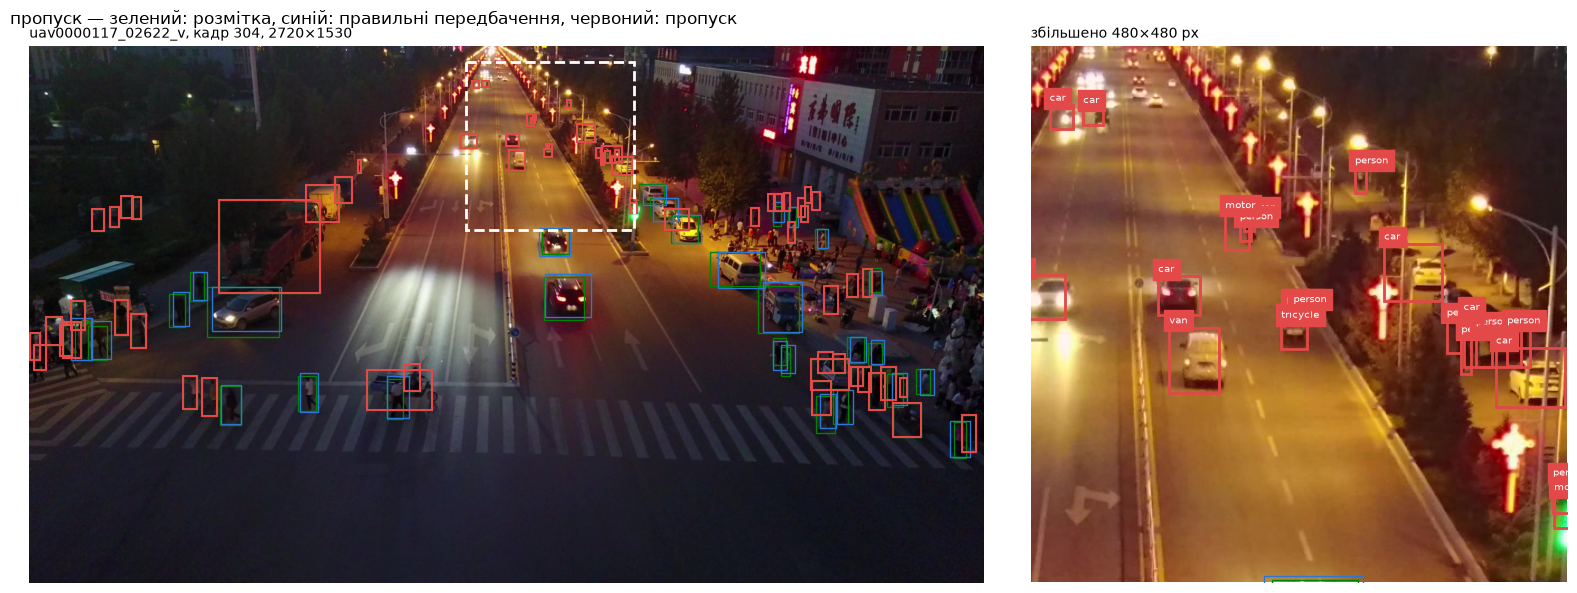

кадр                uav0000117_02622_v / 304
об'єктів                                  93
правильна                                 28
хибна тривога                              0
інше                                      10
пропуск                                   65
плутанина класів                           3
ігнор                                     19
dtype: object

In [9]:
GT_COLOR, OK_COLOR, ERR_COLOR = "#008300", "#2a78d6", "#e34948"


def draw(ax, boxes, color, labels=None, width=1.5, offset=(0, 0)):
    for k, (x1, y1, x2, y2) in enumerate(boxes - np.tile(offset, 2)):
        ax.add_patch(plt.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, edgecolor=color, linewidth=width))
        if labels is not None:
            ax.text(x1, y1 - 2, labels[k], color="white", fontsize=7, backgroundcolor=color, va="bottom", clip_on=True)


def show_error(kind, crop=480):
    image_id = counts[kind].idxmax()
    dt, gt = frames[image_id]
    info = val_images.loc[image_id]
    image = Image.open(DATA / "val" / "images" / info["video"] / Path(info["file_name"]).name)
    if kind == "пропуск":
        errors, labels = xyxy(gt.loc[gt["missed"], "bbox"]), gt.loc[gt["missed"], "category_id"].map(classes).tolist()
    else:
        bad = dt[dt["kind"] == kind]
        errors = xyxy(bad["bbox"])
        labels = [f"{classes[c]} {s:.2f}" + (f" (насправді {t})" if kind == "плутанина класів" else "")
                  for c, s, t in zip(bad["category_id"], bad["score"], bad["true_class"])]
    centers = (errors[:, :2] + errors[:, 2:]) / 2
    cx, cy = centers[(np.abs(centers[:, None] - centers[None]) < crop / 2).all(-1).sum(1).argmax()]
    x0 = int(np.clip(cx - crop / 2, 0, image.width - crop))
    y0 = int(np.clip(cy - crop / 2, 0, image.height - crop))
    inside = ((centers >= (x0, y0)) & (centers < (x0 + crop, y0 + crop))).all(1)
    ok = xyxy(dt.loc[dt["kind"] == "правильна", "bbox"])

    fig, axes = plt.subplots(1, 2, figsize=(16, 6), gridspec_kw={"width_ratios": [image.width / image.height, 1]})
    axes[0].imshow(image)
    draw(axes[0], xyxy(gt["bbox"]), GT_COLOR, width=1)
    draw(axes[0], ok, OK_COLOR, width=1)
    draw(axes[0], errors, ERR_COLOR, width=1.5)
    axes[0].add_patch(plt.Rectangle((x0, y0), crop, crop, fill=False, edgecolor="white", linestyle="--", linewidth=2))
    axes[1].imshow(image.crop((x0, y0, x0 + crop, y0 + crop)))
    draw(axes[1], xyxy(gt["bbox"]), GT_COLOR, width=1, offset=(x0, y0))
    draw(axes[1], ok, OK_COLOR, width=1, offset=(x0, y0))
    draw(axes[1], errors[inside], ERR_COLOR, [l for l, i in zip(labels, inside) if i], width=2, offset=(x0, y0))
    axes[1].set(xlim=(0, crop), ylim=(crop, 0))
    for ax in axes:
        ax.axis("off")
    axes[0].set_title(f"{info['video']}, кадр {info['frame_id']}, {info['width']}×{info['height']}", loc="left", fontsize=10)
    axes[1].set_title(f"збільшено {crop}×{crop} px", loc="left", fontsize=10)
    fig.suptitle(f"{kind} — зелений: розмітка, синій: правильні передбачення, червоний: {kind}", x=0.01, ha="left")
    plt.tight_layout()
    plt.show()
    return pd.Series({"кадр": f"{info['video']} / {info['frame_id']}", "об'єктів": len(gt), **counts.loc[image_id]})


show_error("пропуск")

**Що бачимо:** нічний кадр 2720×1530, 93 об'єкти, знайдено 28, пропущено 65. Пропущені — дрібні об'єкти вздовж дороги вдалині та люди в натовпі праворуч.

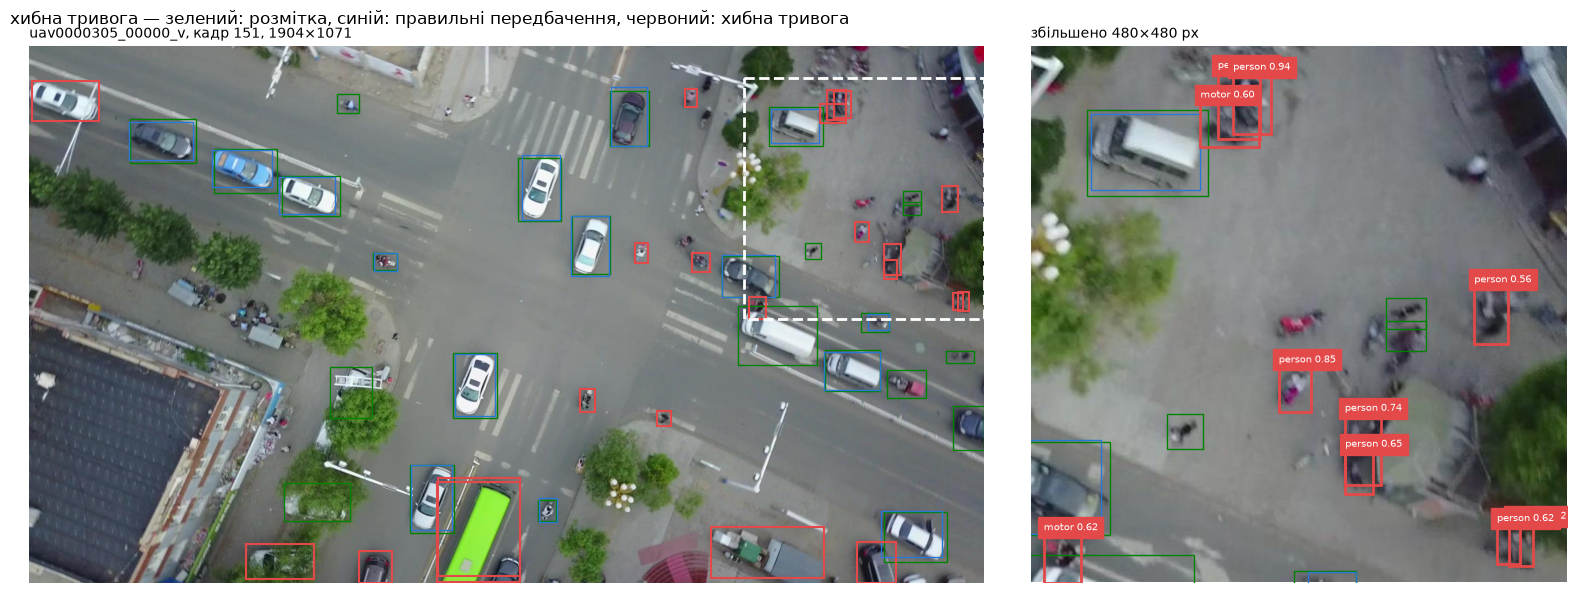

кадр                uav0000305_00000_v / 151
об'єктів                                  25
правильна                                 15
хибна тривога                             22
інше                                       0
пропуск                                   10
плутанина класів                           5
ігнор                                      0
dtype: object

In [10]:
show_error("хибна тривога")

**Що бачимо:** кадр 1904×1071 з дрона згори, 25 розмічених об'єктів і 22 хибні тривоги. Хибні тривоги — person / motor на майданчику праворуч і великий зелений автобус унизу: на кадрі в цих місцях видно людей і транспорт, але розмітки (зеленої рамки) там немає.

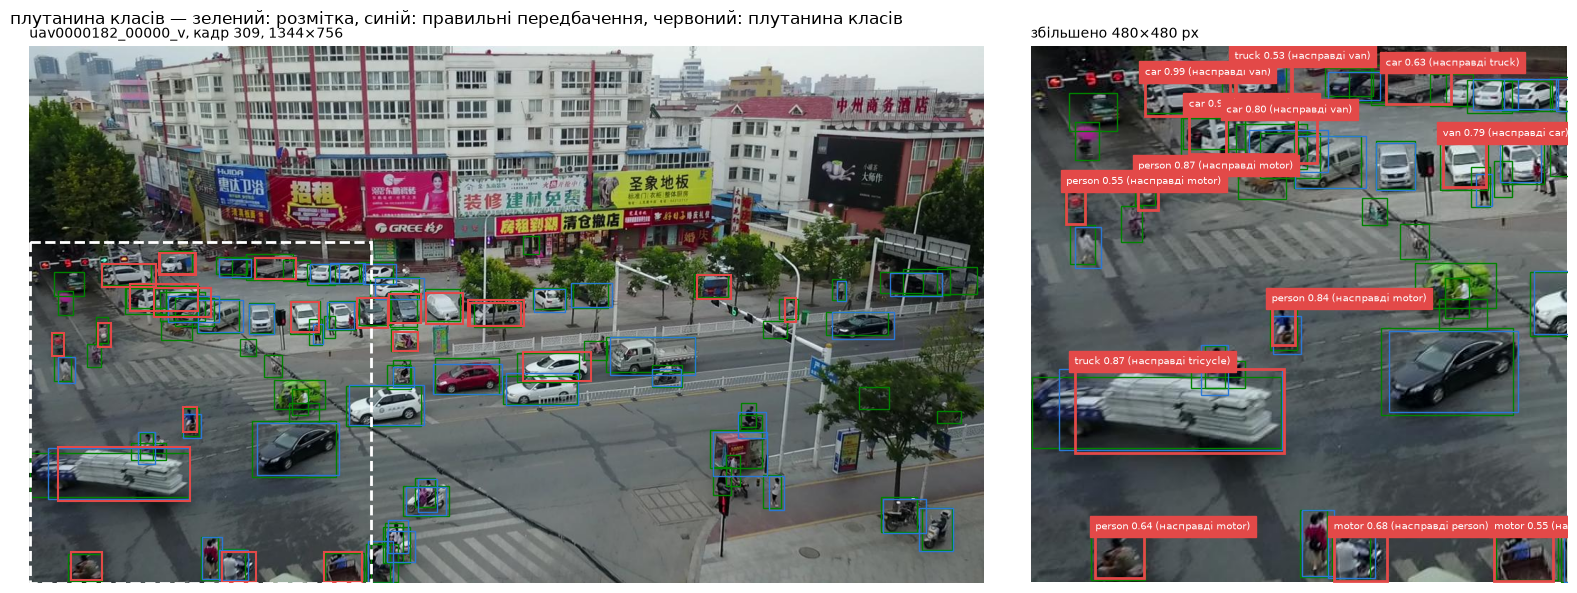

кадр                uav0000182_00000_v / 309
об'єктів                                  83
правильна                                 38
хибна тривога                              3
інше                                      11
пропуск                                   45
плутанина класів                          23
ігнор                                      1
dtype: object

In [11]:
show_error("плутанина класів")

**Що бачимо:** кадр 1344×756, 83 об'єкти, 23 плутанини класів. Пари: car ↔ van, motor → person (людина на мотоциклі), tricycle → truck (навантажений трицикл).

## Джерела

**Бібліотеки**
- pandas, NumPy — таблиці й зіставлення рамок; Matplotlib — графіки й рамки на кадрах; Pillow — читання кадрів.

**Методи**
- Метрики mAP / AP50 / AP_small і межі розмірів small / medium / large — COCO detection evaluation: https://cocodataset.org/#detection-eval; пораховані раніше спільним оцінювачем `hw2_eval.py` (faster-coco-eval).
- Типи помилок (плутанина класів, хибна тривога / фон, пропуск, неточна рамка, дубль) — спрощено за TIDE: D. Bolya et al., *TIDE: A General Toolbox for Identifying Object Detection Errors*, ECCV 2020, arXiv:2008.08115.
- Жадібне зіставлення передбачень із розміткою від найвпевненішого з порогом IoU 0,5 — як у COCO-оцінці.

**Наші рішення**
- Поріг впевненості 0,5; межа «хибної тривоги» IoU < 0,1; рамки з центром в ігнорованій зоні не вважаємо помилками; вибір кадру з найбільшою кількістю помилок кожного типу; розміри для таблиці пропусків (16 / 32 / 64 px).